In [22]:
from IPython.display import Image

# Assignment 2


# Problem 1:


## a: NLP
### Please discuss the recent trend of rapidly increasing sizes of NLP architectures. 

## b: Transfer Learning
### Classify the following example of transfer learning. More exactly, what are the domains and tasks, and which are being changed?

### Source: Using a step counter to monitor exercise in healthy people.

### Target: Using a step counter to indicate recovery progression in a patient


As per slides, the terminology is we have two sets of domains and tasks, which we call the source and the target.

The goal for this is to use an algorithm or dataset (That being the source) to improve the preformance on the target, being a given problem related to source.
Here the step counter is used as a method to understand a baseline for healthy people (potentially), and then the target is comparing this data to their own step counter to see how their recovery process is with regards to a healthy persons steps.

These are two different domains and are not equal. However they can be used to compare, or have a model understand the patterns to better understand the Target (patient recovery)

## c: Attention

### Assume dotproduct attention, and that the hidden states of the encoder layer are [0,1,4],[-1,1,2],[1,1,1],[2,1,1]. If the activation for the previous decoder is [0.1,1,-2], what is the attention-context vector?

From notes in week 8: Most common approach is the dot product attention $a_{ij} = s_{i-1} \cdot h_{j} = s_{i-1}^{T}h_{j}$, attention weights $ \alpha = \frac{e^{a_{ij}}}{\sum_{k} e^{a_{ik}}}$, and the contect vector $ c_{i} = \sum_{j} = \alpha_{ij}h_{j}$

First we calculate the a using dot product attention:

$ a_{ij} = s_0 \cdot h_0 + s_1 \cdot h_1 + s_2 \cdot h_2 $

Therefore:
$$
a_{1} = 0.1 \cdot 0 + 1 \cdot 1 + \left(-2\right) \cdot 4 = -7
$$
$$
a_{2} = 0.1 \cdot \left(-1\right) + 1 \cdot 1 + \left(-2\right) \cdot 1 = -3.1
$$
$$
a_{3} = 0.1 \cdot 1 + 1 \cdot 1 + \left(-2\right) \cdot 1 = -0.9
$$
$$
a_{4} = 0.1 \cdot 2 + 1 \cdot 1 + \left(-2\right) \cdot 1 = -0.8
$$

Next its the softmax layer:

$$
\alpha_{1} = \frac{e^{-7}}{e^{-7} + e^{-3.1} + e^{-0.9} + e^{-0.8}} = \frac{0.000912}{0.901860} = 0.001011
$$
$$
\alpha_{2} = \frac{e^{-3.1}}{e^{-7} + e^{-3.1} + e^{-0.9} + e^{-0.8}} = \frac{0.045049}{0.901860} = 0.049951
$$
$$
\alpha_{3} = \frac{e^{-0.9}}{e^{-7} + e^{-3.1} + e^{-0.9} + e^{-0.8}} = \frac{0.406570}{0.901860} = 0.450811
$$
$$
\alpha_{4} = \frac{e^{-0.8}}{e^{-7} + e^{-3.1} + e^{-0.9} + e^{-0.8}} = \frac{0.449329}{0.901860} = 0.498226
$$

Now the context vector as given above from the slides:
$$
c_{i} = \sum_{j} = \alpha_{ij}h_{j}
$$

$$
c_{1} = 0.001011 \cdot 0 + 0.049951 \cdot \left(-1\right) + 0.450811 \cdot 1 + 0.498226 \cdot 2 = 1.397
$$
$$
c_{2} = 0.001011 \cdot 1 + 0.049951 \cdot 1 + 0.450811 \cdot 1 + 0.498226 \cdot 1 = 1.000
$$
$$
c_{3} = 0.001011 \cdot 4 + 0.049951 \cdot 2 + 0.450811 \cdot 1 + 0.498226 \cdot 1 = 1.053
$$

This gives the attention-context vector as:

$$
c = \left[1.397,\ 1.000,\ 1.053\right]
$$


## d: Transformers

### Explain the 'positional encoding' step for transformers. Why is it done, how is it done?

From the slides, the positional encoding step of the transformation is there to fix the input order sequence, as this information is lost when self-attention is done due to it being encoded.

There are many approaches on how this is done, with one being 'absolute encoding', and another being 'relative encoding'.

'absolute encoding' uses sin and cos, as the encoding positions do not depent on input length, and 'relative encoding' is dependant on relative positions.

So an inpit is given, and a postioning encoding tensor is added to it, written as:

$$
X = X + PE
$$

In accordance to the 'absolute encoding' approach, the following PEs are defined as:

$$
PE\left(pos, 2i\right) = sin \left( \frac{pos}{10000^{\frac{2i}{d_{model}}}}\right)
$$

$$
PE\left(pos, 2i\right) = cos \left( \frac{pos}{10000^{\frac{2i}{d_{model}}}}\right)
$$

pos is similar to $i$, and is a index running along the sequence, where as $i$ itself goes along the input dimensons.

## e: Bounding box detection:
### Given a dataset with two classes; cats and dogs, and the following detections:

### TP = True positive
### FP = False positive

### cat_det = [TP, FP, TP, FP, TP]
### pred_scores_cat = [0.7, 0.3, 0.5, 0.6, 0.5]

### dog_det = [FP, TP, TP, FP, TP, TP]
### pred_scores_dog = [0.4, 0.3, 0.9, 0.5, 0.6, 0.7]


### There are in total 3 cats and 4 dogs in the images.

### Calculate the mean average precision (mAP)

Equation for how to calculate the mean average precision is given by link [geeksforgeeks](https://www.geeksforgeeks.org/computer-vision/mean-average-precision-map-in-computer-vision/)(https://www.geeksforgeeks.org/computer-vision/mean-average-precision-map-in-computer-vision/).

Equations are:

$$
Precision = \frac{TP}{TP + FP}
$$
$$
Recall = \frac{TP}{TP + FN}
$$
$$
mAP = \frac{1}{N} \sum ^{N} _{i=1} AP_i
$$

We have to sort them by confidence value. First cats:
$$
pred-score-cat = [0.7, 0.6, 0.5, 0.5, 0.3]
$$
$$
cat-det = [TP, FP, TP, TP, FP]
$$
$$
cat_{precision} = \frac{TP}{TP + FP} = [\frac{1}{1}=1, \frac{1}{2} = 0.5, \frac{2}{3} = 0.67, \frac{3}{4} = 0.75, \frac{3}{5} = 0.6]
$$
$$
cat_{recall} = \frac{TP}{TP + FN} = [\frac{1}{3}=0.33, \frac{1}{3} = 0.33, \frac{2}{3} = 0.67, \frac{3}{3} = 1, \frac{3}{3} = 1]
$$

Now Dogs:
$$
pred-score-dog = [0.9, 0.7, 0.6, 0.5, 0.4, 0.3]
$$
$$
dog-det = [TP, TP, TP, FP, FP, TP]
$$
$$
dog_{precision} = \frac{TP}{TP + FP} = [\frac{1}{1}=1, \frac{2}{2} = 1, \frac{3}{3} = 1, \frac{3}{4} = 0.75, \frac{3}{5} = 0.6, \frac{4}{6} = 0.67]
$$
$$
dog_{recall} = \frac{TP}{TP + FN} = [\frac{1}{4}=0.25, \frac{2}{4} = 0.5, \frac{3}{4} = 0.75, \frac{3}{4} = 0.75, \frac{3}{4} = 0.75, , \frac{4}{4} = 1]
$$


This has taken a while to understand, so we start with the cats.
We start with the change in recall point, and the first one is where it goes to 0.33.

everything, including this and to the right of, the best value here is 1. The first value is therefore 1.
Next we get a change at $\frac{2}{3}=0.67$ so its this value, and to the right, to find the largetst number form the calculated values, which is 0.75. The final point is the next one, position 4, at $\frac{3}{3}=1$ which is the same largest value before, giving the three values of $1, 0.75, 0.75$ for the cats. This means the AP is:

$$
AP_{cat} = \frac{1}{N} \sum ^{N} _{i=1} AP_i = \frac{1}{3} \left( 1 \right) + \frac{1}{3} \left( 0.75 \right) + \frac{1}{3} \left( 0.75 \right) = 0.33 + 0.25 + 0.25 = 0.83
$$

Now for the dogs.
First recall point is $\frac{1}{4} = 0.25$, where the largest value from the start to right is 1. This continues for the next 3 points, as theyre all TP values. The final point in the collection is the last change in recall, thus giving the last value of $0.67$.
Therefore the 4 values are $1, 1, 1, 0.67$. The dog AP is:

$$
AP_{dog} = \frac{1}{N} \sum ^{N} _{i=1} AP_i = \frac{1}{4} \left( 1 \right) + \frac{1}{4} \left( 1 \right) + \frac{1}{4} \left( 1 \right) + \frac{1}{4} \left( 0.67 \right) = 3 \cdot 0.25 + 0.167 = 0.917
$$

Finally the mean AP is.
$$
mAP = \frac{1}{N} \sum ^{N} _{i=1} AP_i = \frac{0.83 + 0.917}{2} = 0.8735
$$



## f: Semantic segmentation - FCN 1:
### Given an image sized 1024x768x3 (width x height x channels), with 7 classes. What is the size of the target image if targets are one-hot encoded?

If there are 7 classes, than does this not replace the channels and return 7 channels? as there must be a channel for each class. So i would believe it is $\left(1023 \times 768 \times 7\right)$ (get back to this and check)

## g: Semantic segmentation - FCN 2: 
### What is a fully-convolutional network? When is it useful?

An FCN is a netowrk that will output a feature map, where usually the output channels is the number of classes within the data.
An input is given, to which there are only convolutional layers, this outputs to a feature map where the number of channels in the output correspond to the number of classes.

These layers, help generalise the image/data passed through which does mean that minute details are lost. Generalising the images helps the network look at the 'bigger picture' more, and learn the key features of each class/data. A key point is that the size must be the same, hence the need for techniques used to alter the size of the data such as upsampling the output such that it is equal to the input data size. If they are the wrong size, the learned weights are no longer useful. A pooling layer could be used to shrink the number of input spatial dimensions given, and it can be upsampled later such that the output is the same.

This is good for understanding an image at each pixel, where the generalisation helps seperate the diferent items in the image at the correct pixel. An example could be in medical imaging for a tumour, knowing exactly where it is, and being able to distinguish where the tumours bounds stop, as this is good at distinguishing for each pixel, despite the greater detail being lost.

## h:Residual Networks:
### Explain residual layers and their advantage.

Below is a really good image from the slides that helps me understand the residual layers:

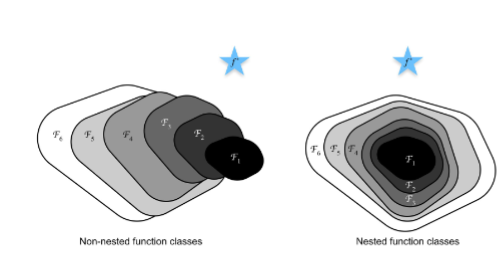

In [23]:
Image(filename='/home/stefan_stringer/FinalSemester/Deep Learning/Assignments/Assignment 2/residuallayers.png')

The left image represents some network architecture, where we just keep adding layers in an attempt to give more complexity and help to approach f*.
The right side, if we stack the layers specifically, such that is a block, we should get closer to this f*, as it improves on the layer that came before. Hence the term residual networks/blocks.

What is done here is that in a residual block/network, there is the ability for an input to forward propgate faster through the connections within the layers. This shortcut means that rather than learning it all, it can just learn the residual difference via a shortcut.
so normally the output is from learning the full mapping, it only needs the difference provided by the shortcut.

## i: Intersection-Over-Union
### Calculate the intersection over union in for these four bounding-boxes and target bounding boxes:

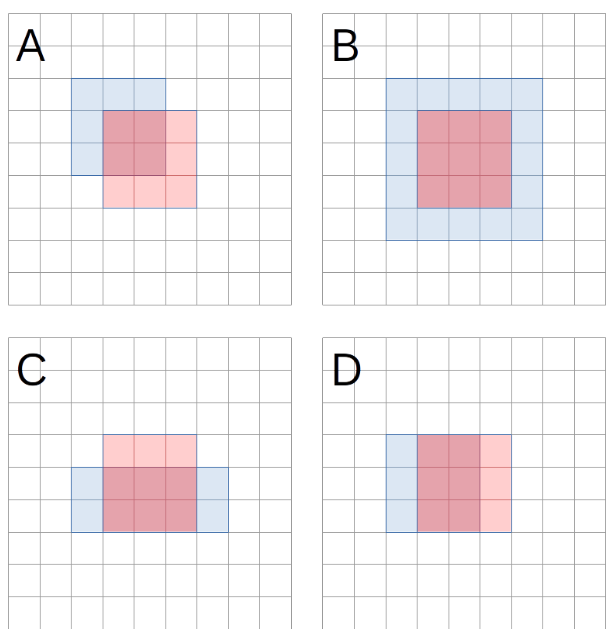

In [24]:
Image(filename='/home/stefan_stringer/FinalSemester/Deep Learning/Assignments/Assignment 2/Problem1image.png')

To calculate this, we take the formula for IoU

$$
IoU = \frac{Area \space of \space Intersection \space of \space two \space boxes}{Area \space of \space Union \space of \space two \space boxes}
$$

For A:
$$
IoU_{A} = \frac{4}{9 + 9 - 4} = \frac{4}{14} = \frac{2}{7} = 0.29
$$

For B:
$$
IoU_{B} = \frac{9}{25 + 9 - 9} = \frac{9}{25} = 0.36
$$

For C:
$$
IoU_{C} = \frac{6}{9 + 10 - 6} = \frac{6}{13} = 0.46
$$

For D:
$$
IoU_{D} = \frac{6}{9 + 9 - 6} = \frac{6}{12} = \frac{1}{2} = 0.5
$$

## j: Variational autoencoders:
### What are the strengths of a variational autoencoder (VAE) compared to an autoencoder (AE)?

An autoencoder is something that has two sides, being the encoding and decoding side which is connected via some bottleneck in the middle.
The dimension of the imput is reduced, and then reconstructed on the otherside and given to an output layer.
Reducing the dimensionality such that the data is compressed and pased through is similar to PCA, such that it wont just memorise the data as the dimensions stay the same.

A Variational autoencoder uses a distribution instead, with a mean and a standard deviation. Instead of a single point, its now a distribution giving many training samples from it, and then decodes it. Every decoding of this gives a genuine sample as it is from a distribution, where as the single point decoding from regular autoencoders can give spaces where there is nothing.

so the comparison is:

Autoencoder:
$$
input \space x \rightarrow latent \space representation \space z = e(x) \rightarrow input \space reconstruction \space d(z)
$$

Variational Autoencoder
$$
input \space x \rightarrow latent \space distribution \space p(x) \rightarrow Sampled \space latent \space representation \space z = p(x) \rightarrow input \space reconstruction \space d(z)
$$

### Problem 2:

n this problem, you will build a waveform detector for 1D time series. Below is shared a piece of code defining a (train) dataset and a test set. As you will see when you open the file, the data is synthetic - a waveform is combined with a background 'noise' signal, allowing virtually infinite training data. 

The task is:

Using the dataset supplied below, create a neural network which can detect the ends of waveforms (marked by '1' in the labels).

You are free to use either GRU, LSTM, xLSTM, state space models or Transformers to do the task.

Dataset generation: data_setup

Use the 'waveformLoader' as data loader for your training data, and 'testX,testy' as the test data. Report your performance as an average loss over the test data and with a plot of 'testy' and 'net(testX)' as a function of time, such as as the figure below. Calculate also the f1 score for your detector.

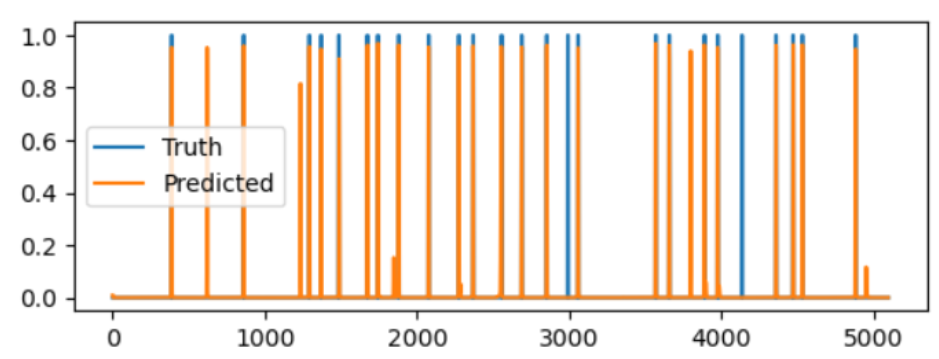

In [25]:
Image(filename='/home/stefan_stringer/FinalSemester/Deep Learning/Assignments/Assignment 2/Problem2image.png')